# NB5 — El banco de prueba y las decisiones de diseño basadas en datos

Varias piezas de la configuración que voló en la v4 no se eligieron a mano. Salen de mediciones **fuera de vuelo** contra una etiqueta de referencia o de lotes piloto con una regla de decisión fijada de antemano. Este cuaderno reconstruye cada una de esas mediciones desde sus datos y muestra la decisión que produjo.

| Sección | Medición | Decisión de diseño | Variable |
|---|---|---|---|
| §1–§5 | Banco del VLM (`vlm_bench`): ¿responde la pregunta del lazo lento? | El VLM no vuela | `STRATEGIC_SOURCE`, `DEADLOCK_STRATEGY` |
| §6 | Misma etiqueta: profundidad monocular, segmentación y reconocimiento por región | La fuente del lazo lento es la profundidad estimada | `STRATEGIC_SOURCE=depth`, `DEADLOCK_STRATEGY=depth` |
| §7 | `map_probe`: reconocimiento de parches del mapa | Juicio por parches con LFM2.5-VL-1.6B | `ROUTE_JUDGE=patches`, `ROUTE_LLM_MODEL_NAME` |
| §8 | `route_bench`: rutas juzgadas contra AirSim | Plan de ruta activo en los escenarios con obstrucción | `ROUTE_PLAN_MODE=vlm` |
| §9 | Lote piloto de fuentes de la capa estratégica (regla prefijada) | Profundidad por costo y seguridad, con avance equivalente | `STRATEGIC_SOURCE=depth` |
| §10 | Dataset de TTC contra la profundidad (ROC, Youden) | Umbrales de evasión y zona segura | `TTC_EVASION_THRESHOLD`, `TTC_SAFE_THRESHOLD` |
| §11 | Dataset D2 de ocupación (ROC, Youden) | Umbral de ocupación que bloquea | `OBSTACLE_OCCUPANCY_BLOCKED` |

**Datos.** Banco v2 en `airsim-runs/test/vlm_bench/v2/` y `map_probe/`; lote piloto en `airsim-runs/lote_estrategico/`; TTC en `airsim-runs/test/ttc/`; D2 en `d2_dataset/`. No hace falta AirSim ni Ollama: las respuestas del modelo y las etiquetas están guardadas.

## §0 — Configuración

In [1]:
import os, sys, json, math, glob, collections, base64
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / 'config' / '.env').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
LOOP = ROOT / 'airsim-loop'
sys.path.insert(0, str(LOOP))
sys.path.insert(0, str(LOOP / 'experiments' / 'vlm_bench'))
import report as R
import labels as LB
from common import read_jsonl
from evaluate import valid, ALIGN_MIN, scan_groups
from questions import catalog, _grid_image, CELLS

BENCH = ROOT / 'airsim-runs' / 'test' / 'vlm_bench' / 'v2'
MAPPROBE = ROOT / 'airsim-runs' / 'test' / 'vlm_bench' / 'map_probe'
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 200)
print('criterio de pase: exactitud balanceada >=', R.PASS_MIN, 'y limite inferior del IC 95 % sobre el azar;',
      'bootstrap por corrida con', R.BOOTSTRAP_N, 'remuestreos; respuesta "constante" si la mas frecuente >=', R.CONSTANT_SHARE)

criterio de pase: exactitud balanceada >= 0.65 y limite inferior del IC 95 % sobre el azar; bootstrap por corrida con 2000 remuestreos; respuesta "constante" si la mas frecuente >= 0.9


## §1 — Por qué un banco y no un lote de vuelo

La pregunta previa a cualquier lote es si la fuente del lazo lento **sabe responder lo que el lazo le pregunta**: si un sector está libre a 15 m, si un rumbo es transitable o si un tramo de mapa es calle. Un lote de vuelo no la responde. El resultado de una misión mezcla percepción, guiado, lazo rápido, atascos y azar, y con pocas semillas una fuente que responde al azar puede empatar con una que acierta. El banco aísla el juicio: compara, muestra por muestra, la respuesta con una **etiqueta de referencia** calculada con la profundidad del simulador en la misma pose. La profundidad solo se lee acá, nunca en el lazo de vuelo.

Tres reglas lo mantienen como medición generalista y no como ajuste a un escenario (informe §10.13.1):

1. *Prompts* fijos, iguales a los de vuelo e independientes del escenario.
2. La respuesta se lee **tal como sale**: el criterio de pase no usa umbrales calibrados sobre los datos. El AUC, calculado con las probabilidades de los *logprobs*, es solo diagnóstico.
3. Una pregunta que no pasa se descarta en lugar de compensarse con reglas.

## §2 — El conjunto de muestras

`dataset.py` toma poses registradas en vuelo de las corridas de `citysim_pilot` que tienen telemetría y los dos videos. Hay tres clases de muestra:

- **strategic**: cada consulta de la capa estratégica, con la foto enviada y la respuesta que dio el VLM en vuelo.
- **scan**: cada rumbo de cada barrido de deadlock.
- **trajectory**: ciclos sin consulta a ≥ 8 m de altura, de-duplicados por celda de pose (2 m × 2 m × 2 m × 20°), para que un dron trabado cientos de ciclos en un mismo lugar cuente una sola vez.

`ground_truth.py` reubica el dron en cada pose y captura RGB y profundidad. Una muestra es **válida** si la cámara no quedó dentro de la geometría, si la captura se estabilizó (Unreal carga la escena por zonas) y si la imagen reproducida coincide con la registrada en vuelo (correlación ≥ 0.5).

poses candidatas: 6926 de 21 corridas -> Counter({'trajectory': 5918, 'scan': 579, 'strategic': 429})
reproducidas en AirSim (con etiqueta): 1908 -> Counter({'trajectory': 900, 'scan': 579, 'strategic': 429})


,muestras
valida,915
pose mal reproducida (correlacion < 0.5),422
captura inestable,381
camara dentro de la geometria,190


validas: 915; barridos completos: 53
(report.py cuenta los motivos sin exclusion mutua -una muestra puede ser inestable y estar mal reproducida-; aca cada muestra queda con el primer motivo que la excluye)


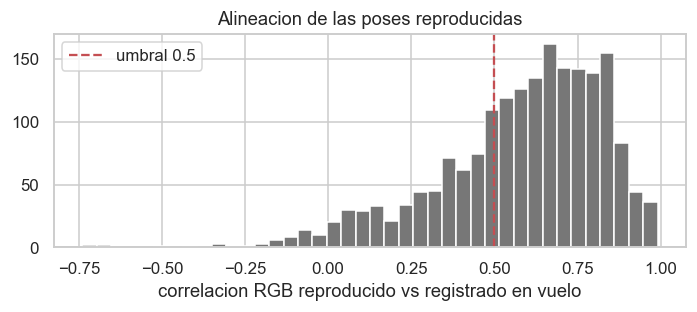

In [2]:
samples = read_jsonl(BENCH / 'samples.jsonl')
sgt = read_jsonl(BENCH / 'samples_gt.jsonl')
print(f"poses candidatas: {len(samples)} de {len({s['run'] for s in samples})} corridas -> {collections.Counter(s['kind'] for s in samples)}")
print(f"reproducidas en AirSim (con etiqueta): {len(sgt)} -> {collections.Counter(s['kind'] for s in sgt)}")

def motivo(s):
    rp = s.get('replay') or {}
    if s['gt'].get('inside'): return 'camara dentro de la geometria'
    if not rp.get('stable'): return 'captura inestable'
    a = rp.get('align_ncc')
    if a is not None and a < ALIGN_MIN: return 'pose mal reproducida (correlacion < 0.5)'
    return 'valida'
mot = pd.Series([motivo(s) for s in sgt]).value_counts()
display(mot.to_frame('muestras'))
assert mot['valida'] == sum(valid(s) for s in sgt)
ncc = [s['replay']['align_ncc'] for s in sgt if (s.get('replay') or {}).get('align_ncc') is not None]
val = [s for s in sgt if valid(s)]
print(f"validas: {len(val)}; barridos completos: {len(scan_groups(sgt))}")
print('(report.py cuenta los motivos sin exclusion mutua -una muestra puede ser inestable y estar mal reproducida-; '
      'aca cada muestra queda con el primer motivo que la excluye)')
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.hist(ncc, bins=40, color='#777'); ax.axvline(ALIGN_MIN, color='r', ls='--', label='umbral 0.5')
ax.set_xlabel('correlacion RGB reproducido vs registrado en vuelo'); ax.legend(); ax.set_title('Alineacion de las poses reproducidas')
plt.tight_layout(); plt.show()

## §3 — La etiqueta de referencia

`labels.labels_from_depth()` usa **la misma geometría que ve la fuente en vuelo**: el recorte cuadrado central del fotograma y su grilla 3×3 por tercios. Por sector toma el percentil 5 de la profundidad planar (lo más cercano, sin píxeles sueltos). Un sector es **libre** si ese percentil es ≥ 15 m, la distancia que se le pide juzgar a la fuente y a la que se fija la sub-meta. De ahí salen también las etiquetas de las preguntas derivadas: centro libre, lado por el que termina el obstáculo, espacio por encima y dirección más abierta.

Abajo, una muestra válida con la imagen reproducida, su profundidad (guardada reducida por mínimo en bloques de 4×4, que no borra obstáculos finos) y la etiqueta recalculada.

muestra seed_99_20260929T143756Z_c1196_tr | clase trajectory | pose {'x': 34.8, 'y': -5.2, 'z': -9.7, 'yaw_deg': 161.8, 'pitch_deg': -1.6, 'roll_deg': 0.3}
RGB (720, 1080, 3) | profundidad guardada (180, 270)


,p5 guardado (m),p5 recalculado (m),libre (guardado),libre (recalculado)
A1,12.67,12.64,False,False
B1,23.3,23.17,True,True
C1,55.62,55.34,True,True
A2,12.34,12.26,False,False
B2,22.89,22.58,True,True
C2,7.53,7.34,False,False
A3,12.31,12.24,False,False
B3,17.03,16.94,True,True
C3,17.03,17.01,True,True


{'center_free': 'si', 'edge_side': None, 'top_clear': None, 'open_dir': 'centro'}


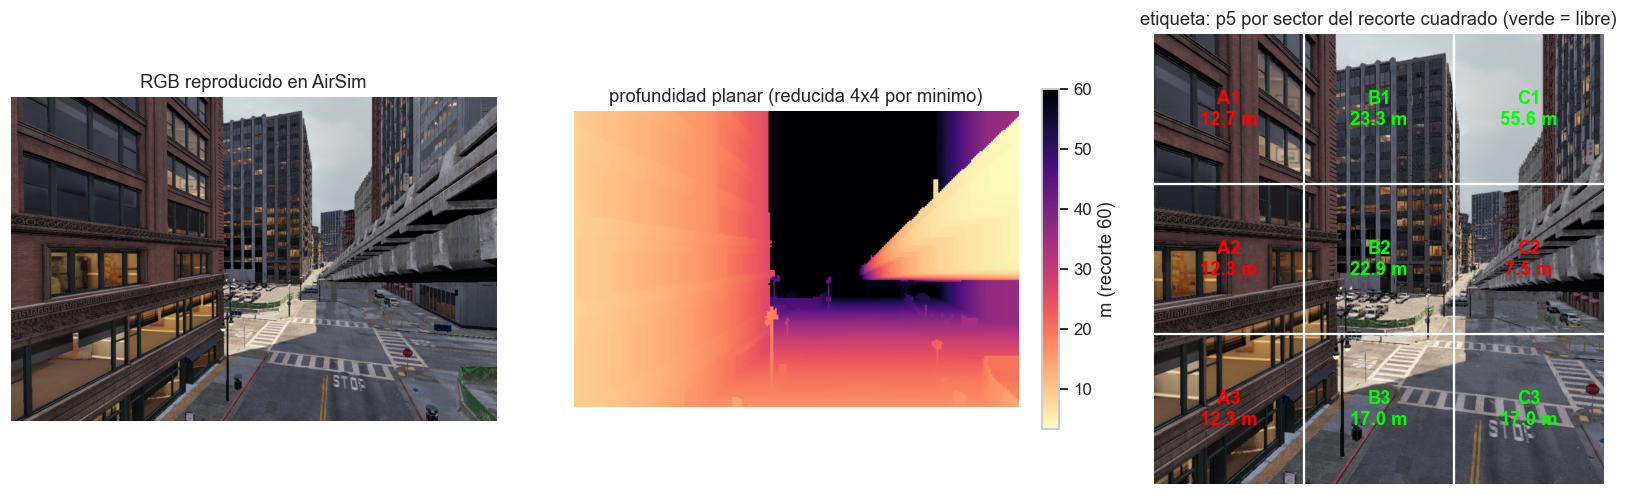

In [3]:
res_rows = read_jsonl(BENCH / 'results.jsonl')
grid_ids = {r['id'] for r in res_rows if r['question'] == 'grid_prod'}
cand = [s for s in val if s['id'] in grid_ids and 3 <= sum(s['gt']['cell_free'].values()) <= 6]
s0 = cand[len(cand) // 3]
rgb = cv2.cvtColor(cv2.imread(str(BENCH / s0['replay']['rgb'])), cv2.COLOR_BGR2RGB)
depth = np.load(BENCH / 'replay' / f"{s0['id']}_depth.npz")['depth'].astype(np.float32)
lab = LB.labels_from_depth(depth)
print('muestra', s0['id'], '| clase', s0['kind'], '| pose', {k: round(v, 1) for k, v in s0['pose'].items()})
print('RGB', rgb.shape, '| profundidad guardada', depth.shape)
tab = pd.DataFrame({c: {'p5 guardado (m)': s0['gt']['cells'][c]['p5'], 'p5 recalculado (m)': round(lab['cells'][c]['p5'], 2),
                        'libre (guardado)': s0['gt']['cell_free'][c], 'libre (recalculado)': lab['cell_free'][c]} for c in CELLS}).T
display(tab)
print({k: lab[k] for k in ('center_free', 'edge_side', 'top_clear', 'open_dir')})

def sq(a):
    h, w = a.shape[:2]; s_ = min(h, w); x0, y0 = (w - s_) // 2, (h - s_) // 2
    return a[y0:y0 + s_, x0:x0 + s_]
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
ax[0].imshow(rgb); ax[0].set_title('RGB reproducido en AirSim'); ax[0].axis('off')
im = ax[1].imshow(np.clip(depth, 0, 60), cmap='magma_r'); plt.colorbar(im, ax=ax[1], fraction=0.035, label='m (recorte 60)')
ax[1].set_title('profundidad planar (reducida 4x4 por minimo)'); ax[1].axis('off')
c_ = sq(rgb); side = c_.shape[0]
ax[2].imshow(c_)
for k in (1, 2):
    ax[2].axvline(k * side / 3, color='w'); ax[2].axhline(k * side / 3, color='w')
for ci, cc_ in enumerate('ABC'):
    for ri, rr in enumerate('123'):
        p5 = s0['gt']['cells'][cc_ + rr]['p5']
        ax[2].text((ci + .5) * side / 3, (ri + .5) * side / 3, f'{cc_}{rr}\n{p5:.1f} m', ha='center', va='center',
                   color='lime' if p5 >= 15 else 'red', weight='bold')
ax[2].set_title('etiqueta: p5 por sector del recorte cuadrado (verde = libre)'); ax[2].axis('off')
plt.tight_layout(); plt.show()

## §4 — Las preguntas y lo que vio el modelo

`questions.py` define cada pregunta: a qué muestras aplica, cómo arma la imagen y el *prompt*, su esquema JSON (decodificación restringida, como en vuelo), la etiqueta verdadera y cómo se lee la respuesta.

- `grid_prod` es la pregunta de vuelo tal cual: grilla 3×3, marca de la meta, «free» o «blocked» por sector.
- `grid_perm` repite la misma pregunta con las etiquetas de los sectores permutadas. Si la respuesta por posición física no cambia al cambiar las etiquetas, el modelo responde a la posición en la imagen y no a la escena.
- `scan_prod` y `scan_perm` hacen lo mismo con las imágenes de un barrido.
- Las preguntas simples (`centro_libre`, `borde_lateral`, `borde_superior`, `direccion_abierta`) son formas más fáciles de la misma información.

preguntas del catalogo: ['grid_prod', 'grid_perm', 'centro_libre', 'borde_lateral', 'borde_superior', 'direccion_abierta', 'scan_prod', 'scan_perm']


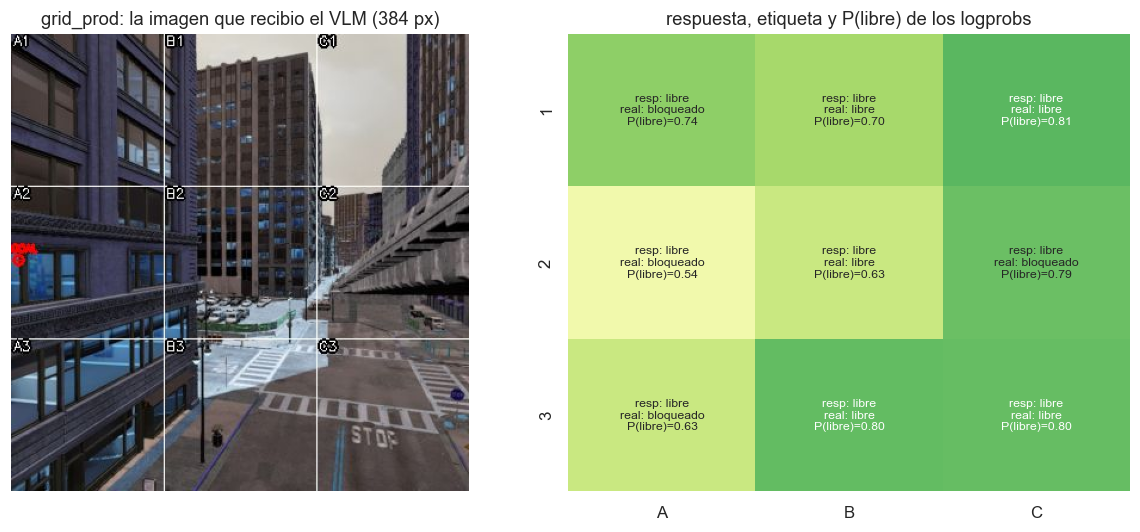

latencia de esta consulta: 837.3 ms


In [4]:
cat = catalog()
print('preguntas del catalogo:', list(cat))
b64 = _grid_image(rgb, s0, 384)
grid_img = cv2.cvtColor(cv2.imdecode(np.frombuffer(base64.b64decode(b64), np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
r0 = next(r for r in res_rows if r['question'] == 'grid_prod' and r['id'] == s0['id'])
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(grid_img); ax[0].set_title('grid_prod: la imagen que recibio el VLM (384 px)'); ax[0].axis('off')
M = np.zeros((3, 3)); A = np.empty((3, 3), dtype=object)
for ci, cc_ in enumerate('ABC'):
    for ri, rr in enumerate('123'):
        k = cc_ + rr
        M[ri, ci] = r0['probs'][k]['libre']
        A[ri, ci] = f"resp: {r0['answer'][k]}\nreal: {r0['truth'][k]}\nP(libre)={r0['probs'][k]['libre']:.2f}"
sns.heatmap(M, annot=A, fmt='', cmap='RdYlGn', vmin=0, vmax=1, cbar=False, ax=ax[1], xticklabels=list('ABC'), yticklabels=list('123'),
            annot_kws={'fontsize': 8})
ax[1].set_title('respuesta, etiqueta y P(libre) de los logprobs')
plt.tight_layout(); plt.show()
print('latencia de esta consulta:', r0['latency_ms'], 'ms')

## §5 — Métricas, criterio de pase y resultado del VLM

- **Exactitud balanceada.** Es el promedio de la sensibilidad por clase. Contestar siempre lo mismo da exactamente 1/k con k clases: no premia a la clase mayoritaria.
- **IC 95 % por *bootstrap* por corrida.** Las vistas de una misma corrida no son independientes, así que se remuestrean **corridas enteras** (conglomerados), no muestras.
- **Pase.** La pregunta pasa si la exactitud balanceada es ≥ 0.65 **y** el límite inferior del IC supera el azar.
- **Diagnóstico.** El AUC, con la probabilidad de la opción positiva, indica si hay información latente que la respuesta no expresa. No configura el vuelo.

Primero, el cálculo abierto para `grid_prod` (todas las celdas juntas). Después, la tabla completa con `report.build()`.

In [5]:
rows = [r for r in res_rows if r['question'] == 'grid_prod' and not r.get('error') and r.get('answer')]
flat = [(r['run'], r['truth'][c], r['answer'][c], r['probs'][c]['libre']) for r in rows for c in CELLS]
truth = [t for _, t, _, _ in flat]; pred = [p for _, _, p, _ in flat]
sens = {cl: np.mean([p == cl for t, p in zip(truth, pred) if t == cl]) for cl in ('libre', 'bloqueado')}
ba = R.balanced_accuracy(truth, pred)
lo, hi = R.cluster_bootstrap_ci([(run, t, p) for run, t, p, _ in flat])
au = R.auc([pr for *_, pr in flat], [t == 'libre' for t in truth])
print(f"{len(rows)} muestras x 9 sectores = {len(flat)} juicios de {len({r['run'] for r in rows})} corridas")
print(f"sensibilidad por clase: {sens} -> exactitud balanceada = {ba:.3f}  IC 95 % por corrida [{lo:.3f}, {hi:.3f}]  azar 0.5")
print(f"responde 'libre' en {np.mean([p == 'libre' for p in pred]):.0%} de los sectores; realmente libres: {np.mean([t == 'libre' for t in truth]):.0%}")
print(f"AUC de P(libre) (diagnostico): {au:.3f}  ->  pasa: {ba >= R.PASS_MIN and lo > 0.5}")

120 muestras x 9 sectores = 1080 juicios de 19 corridas
sensibilidad por clase: {'libre': np.float64(0.841845140032949), 'bloqueado': np.float64(0.21141649048625794)} -> exactitud balanceada = 0.527  IC 95 % por corrida [0.502, 0.552]  azar 0.5
responde 'libre' en 82% de los sectores; realmente libres: 56%
AUC de P(libre) (diagnostico): 0.533  ->  pasa: False


In [6]:
metrics = R.build(BENCH)
filas = []
for k, q in metrics['questions'].items():
    if k.startswith('ruta_mapa'):
        continue
    filas.append({'pregunta': k, 'n': q.get('n', q.get('n_images')), 'exactitud bal.': q.get('balanced_accuracy'),
                  'IC bajo': q.get('ci_low'), 'IC alto': q.get('ci_high'), 'azar': q.get('chance'), 'pasa': q.get('passes'),
                  'resp. mas frecuente': (q.get('answers') or {}).get('top_answer'),
                  'participacion': (q.get('answers') or {}).get('top_share'), 'constante': (q.get('answers') or {}).get('constant'),
                  'AUC (diag.)': q.get('auc'), 'latencia (ms)': q.get('latency_ms_mean')})
tq = pd.DataFrame(filas).round(3)
display(tq)
print('preguntas que pasan el criterio:', int(tq['pasa'].fillna(False).sum()), 'de', len(tq))
d = metrics['dataset']
print(f"dataset segun report.build: {d['samples']} muestras, {d['valid']} validas (dentro {d['inside_geometry']}, inestables {d['unstable']}, "
      f"mal reproducidas {d['misaligned']})")

,pregunta,n,exactitud bal.,IC bajo,IC alto,azar,pasa,resp. mas frecuente,participacion,constante,AUC (diag.),latencia (ms)
0,borde_lateral@384/replay,180,0.333,0.333,0.333,0.333,False,izquierda,1.000,True,NaN,354.623
1,borde_superior@384/replay,120,0.533,0.497,0.584,0.500,False,si,0.950,True,0.687,361.982
2,centro_libre@384/replay,120,0.500,0.500,0.500,0.500,False,si,1.000,True,0.524,343.108
3,direccion_abierta@384/replay,208,0.321,0.276,0.359,0.250,False,izquierda,0.615,False,NaN,363.984
4,grid_perm@384/replay,120,0.507,0.487,0.526,0.500,False,libre,0.845,False,0.510,879.164
5,grid_prod@384/replay,120,0.527,0.502,0.552,0.500,False,libre,0.819,False,0.533,875.012
6,scan_perm@384/replay,22,0.500,0.500,0.500,0.500,False,True,1.000,True,0.923,3131.608
7,scan_prod@384/replay,14,0.500,0.500,0.500,0.500,False,True,1.000,True,0.042,2615.754


preguntas que pasan el criterio: 0 de 8
dataset segun report.build: 1908 muestras, 915 validas (dentro 190, inestables 384, mal reproducidas 589)


**Ninguna pregunta pasa.** Tres son constantes: el modelo da la misma respuesta en ≥ 90 % de los casos. Las demás quedan a pocos puntos del azar. El AUC de la grilla (≈ 0.53) muestra que tampoco hay señal latente en las probabilidades. Los barridos declaran transitable todo rumbo; sus AUC (sobre 14 y 22 barridos) cambian de extremo a extremo con el orden de las imágenes y no son interpretables.

¿A qué responde entonces el modelo? A la **posición** del sector en la imagen:

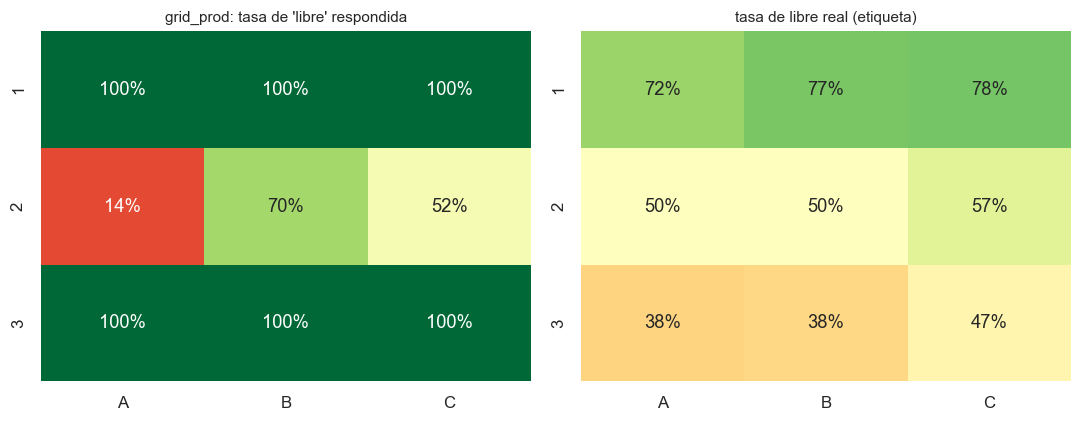

acuerdo por posicion fisica entre grid_prod y grid_perm: 75% de los sectores


In [7]:
gp = metrics['questions']['grid_perm@384/replay']
rate_ans = {c: np.mean([r['answer'][c] == 'libre' for r in rows]) for c in CELLS}
rate_true = {c: np.mean([r['truth'][c] == 'libre' for r in rows]) for c in CELLS}
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for axi, rate, tit in ((ax[0], rate_ans, "grid_prod: tasa de 'libre' respondida"), (ax[1], rate_true, 'tasa de libre real (etiqueta)')):
    Mx = np.array([[rate[c + r] for c in 'ABC'] for r in '123'])
    sns.heatmap(Mx, annot=True, fmt='.0%', cmap='RdYlGn', vmin=0, vmax=1, ax=axi, xticklabels=list('ABC'), yticklabels=list('123'), cbar=False)
    axi.set_title(tit, fontsize=10)
plt.tight_layout(); plt.show()
print(f"acuerdo por posicion fisica entre grid_prod y grid_perm: {gp['permutation']['agreement']:.0%} de los sectores")

Dos datos se combinan. El acuerdo alto entre la grilla normal y la permutada descarta que el modelo responda a la **etiqueta** dibujada en cada sector; la exactitud en el azar descarta que responda a la **escena**. Queda la posición en la imagen. Las filas 1 y 3 salen «libre» en el 100 % de los casos, sin importar la escena. En la fila del medio la respuesta depende de la columna más que de lo que hay delante. **Consecuencia para el vuelo:** con el VLM como fuente, la sub-meta saldría de la posición de las celdas y no de la escena. La fila de abajo, siempre «libre», haría descender al dron hacia las estructuras, y el barrido declararía transitables todos los rumbos.

**Decisión:** el VLM, en régimen *zero-shot* y a bordo, no se usa como fuente de decisión táctica. Es la respuesta negativa al objetivo 3 de la tesis (informe §11.0).

## §6 — La misma pregunta con otras fuentes

Si el VLM no juzga distancias, quedan dos preguntas. ¿Reconoce al menos *qué hay* en cada sector (`region_probe`)? ¿Lo hace mejor una red chica que solo ve el RGB (`seg_depth_probe`)? Las tres fuentes se miden con la **misma etiqueta** y la misma geometría:

- **VLM por región**: el recorte del sector y la pregunta «¿qué lo llena?», con cinco clases. Abierto = cielo, edificios lejanos o calle.
- **Profundidad monocular** (Depth Anything V2 Metric Outdoor Small): p5 estimado por sector; libre si es ≥ 15 m, la misma regla que la etiqueta.
- **Segmentación** (`yolo26n-sem`, Cityscapes): libre si la fracción de píxeles de obstáculo es < 5 %.

Las reglas se fijaron antes de correr la prueba.

In [8]:
sd_all = read_jsonl(BENCH / 'seg_depth_results.jsonl')
sd = [r for r in sd_all if '_scan' not in r['id']]          # fotogramas sueltos; los barridos se analizan aparte
sd_scan = [r for r in sd_all if '_scan' in r['id']]
rg = read_jsonl(BENCH / 'region_results.jsonl')
run_of = {r['id']: r['run'] for r in sd}
D = pd.DataFrame([{'id': r['id'], 'run': r['run'], 'cell': c, 'libre': v['truth_open'], 'd_p5': v['d_p5'], 'obst': v['obst'], 'sky': v['sky']}
                  for r in sd for c, v in r['cells'].items()])
V = pd.DataFrame([{'id': r['id'], 'cell': c, 'p_vlm_grid': r['probs'][c]['libre'], 'resp_vlm_grid': r['answer'][c] == 'libre'}
                  for r in rows for c in CELLS])
# region_probe se corrio en dos modos: 'marker' (registros sin la clave mode) y 'crop' (el viable en vuelo)
G = pd.DataFrame([{'id': r['id'], 'cell': r['cell'], 'p_vlm_region': r['p_open'], 'resp_vlm_region': r['pred_open'], 'modo': r.get('mode', 'marker')}
                  for r in rg if r.get('p_open') is not None])
G = G[G['modo'] == 'crop']
DS_ = pd.DataFrame([{'id': r['id'], 'run': r['run'], 'cell': 'B2', 'libre': r['cells']['B2']['truth_open'], 'd_p5': r['cells']['B2']['d_p5']}
                    for r in sd_scan])
J = D.merge(V, on=['id', 'cell']).merge(G[['id', 'cell', 'p_vlm_region', 'resp_vlm_region']], on=['id', 'cell'], how='left')
print(f"profundidad y segmentacion: {len(D)} sectores ({D['id'].nunique()} muestras); con las {J['id'].nunique()} muestras de las preguntas del VLM: {len(J)} sectores")

def fila(nombre, score, regla, df):
    y = df['libre'].tolist()
    lo_, hi_ = R.cluster_bootstrap_ci(list(zip(df['run'], y, regla)))
    return {'fuente': nombre, 'sectores': len(df), 'exactitud bal. (regla fija)': R.balanced_accuracy(y, list(regla)),
            'IC bajo': lo_, 'IC alto': hi_, 'AUC': R.auc(list(score), y)}
J['run'] = J['id'].map(run_of)
tab6 = pd.DataFrame([
    fila('VLM grilla (grid_prod)', J['p_vlm_grid'], J['resp_vlm_grid'], J),
    fila('VLM por region (region_probe)', J['p_vlm_region'].fillna(0.5), J['resp_vlm_region'].fillna(False).astype(bool), J),
    fila('segmentacion: 1 - obstaculo', 1 - J['obst'], J['obst'] < 0.05, J),
    fila('profundidad: p5 estimado', J['d_p5'], J['d_p5'] >= 15, J),
    fila(f"profundidad: p5 estimado ({D['id'].nunique()} muestras)", D['d_p5'], D['d_p5'] >= 15, D),
    fila(f'profundidad: p5 de B2 en barridos ({len(DS_)} imagenes)', DS_['d_p5'], DS_['d_p5'] >= 15, DS_),
]).round(3)
tab6['pasa'] = (tab6['exactitud bal. (regla fija)'] >= R.PASS_MIN) & (tab6['IC bajo'] > 0.5)
display(tab6)

profundidad y segmentacion: 5625 sectores (625 muestras); con las 120 muestras de las preguntas del VLM: 1080 sectores


,fuente,sectores,exactitud bal. (regla fija),IC bajo,IC alto,AUC,pasa
0,VLM grilla (grid_prod),1080,0.527,0.502,0.552,0.533,False
1,VLM por region (region_probe),1080,0.485,0.444,0.519,0.616,False
2,segmentacion: 1 - obstaculo,1080,0.449,0.406,0.488,0.504,False
3,profundidad: p5 estimado,1080,0.763,0.726,0.811,0.839,True
4,profundidad: p5 estimado (625 muestras),5625,0.748,0.722,0.775,0.831,True
5,profundidad: p5 de B2 en barridos (290 imagenes),290,0.750,0.682,0.821,0.871,True


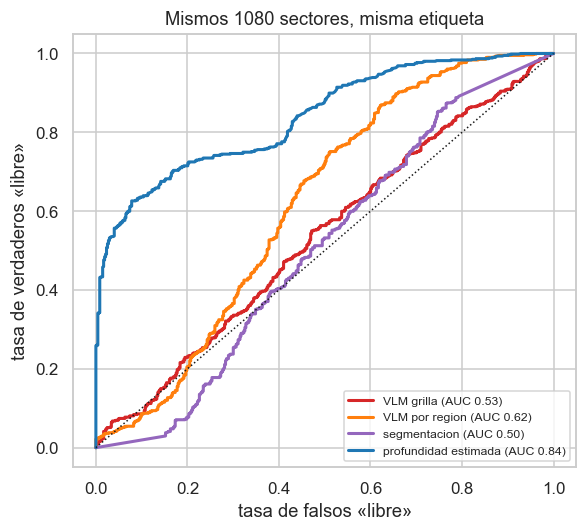

In [9]:
def roc(score, y):
    s = np.asarray(score, float); y = np.asarray(y, bool)
    th = np.r_[np.inf, np.sort(np.unique(s))[::-1]]
    return [np.mean(s[~y] >= t) for t in th], [np.mean(s[y] >= t) for t in th]
fig, ax = plt.subplots(figsize=(5.5, 5))
for nombre, sc, col in (('VLM grilla', J['p_vlm_grid'], '#d62728'), ('VLM por region', J['p_vlm_region'].fillna(0.5), '#ff7f0e'),
                        ('segmentacion', 1 - J['obst'], '#9467bd'), ('profundidad estimada', J['d_p5'], '#1f77b4')):
    fp, tp = roc(sc, J['libre'])
    ax.plot(fp, tp, color=col, lw=2, label=f"{nombre} (AUC {R.auc(list(sc), J['libre'].tolist()):.2f})")
ax.plot([0, 1], [0, 1], 'k:', lw=1); ax.set_xlabel('tasa de falsos «libre»'); ax.set_ylabel('tasa de verdaderos «libre»')
ax.set_title('Mismos 1080 sectores, misma etiqueta'); ax.legend(fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

**Decisión.** La profundidad estimada es la única fuente que pasa el criterio con la regla fija (≈ 75 % de exactitud balanceada, AUC ≈ 0.84), también en las imágenes de barrido, con el sector central B2 que decide el rumbo. Tarda ~80 ms por imagen en la GPU compartida con Ollama, frente a ~0.9 s de la grilla del VLM. La segmentación queda en el azar: la clase de un píxel no dice a qué distancia está. Se configura `STRATEGIC_SOURCE=depth` y `DEADLOCK_STRATEGY=depth`, y el grafo solo levanta el servicio del VLM si alguna capa lo pide (`graph.py`, `need_vlm`).

## §7 — `map_probe`: ¿reconoce el VLM qué hay en un parche del mapa?

Antes de preguntar por una **ruta** se mide si el modelo reconoce lo que hay en un **lugar** del mapa cenital. Los centros de parche se sortean en la zona de la misión y la etiqueta se toma mirando el parche desde arriba con la profundidad: `ground` si menos del 10 % está a más de 2.5 m sobre el suelo, `raised` si más del 70 %. Se hacen tres formas de pregunta:

- `yesno`: «¿está a nivel de calle?»;
- `pair_sb` / `pair_bs`: «calle o edificio», en los dos órdenes (mide el sesgo por posición de la opción);
- `multi`: cinco clases.

Cada una se prueba con varios modelos y cuantizaciones.

parches etiquetados: {'ground': 64, 'raised': 54, 'mixed': 42}


,modelo,pregunta,n,exactitud bal.,AUC P(calle),respuestas
0,hf.co/LiquidAI/LFM2.5-VL-1.6B-Extract-GGUF:Q4_K_M,multi,60,0.50,0.83,{'parking': 60}
1,hf.co/LiquidAI/LFM2.5-VL-1.6B-Extract-GGUF:Q4_K_M,pair_bs,60,0.50,0.53,{'building': 60}
2,hf.co/LiquidAI/LFM2.5-VL-1.6B-Extract-GGUF:Q4_K_M,pair_sb,60,0.55,0.53,"{'street': 33, 'building': 27}"
3,hf.co/LiquidAI/LFM2.5-VL-1.6B-Extract-GGUF:Q4_K_M,yesno,60,0.50,0.75,{'no': 60}
4,lfm2.5-vl-1.6b:q4km-ctx8k,multi,60,0.65,0.79,"{'parking': 43, 'building': 17}"
5,lfm2.5-vl-1.6b:q4km-ctx8k,pair_bs,60,0.50,0.49,{'building': 60}
6,lfm2.5-vl-1.6b:q4km-ctx8k,pair_sb,60,0.50,0.55,{'building': 60}
7,lfm2.5-vl-1.6b:q4km-ctx8k,yesno,60,0.50,0.58,{'yes': 60}
8,liquidai/lfm2.5-vl-1.6b,multi,60,0.72,0.80,"{'parking': 25, 'building': 35}"
9,liquidai/lfm2.5-vl-1.6b,pair_bs,60,0.50,0.56,{'building': 60}


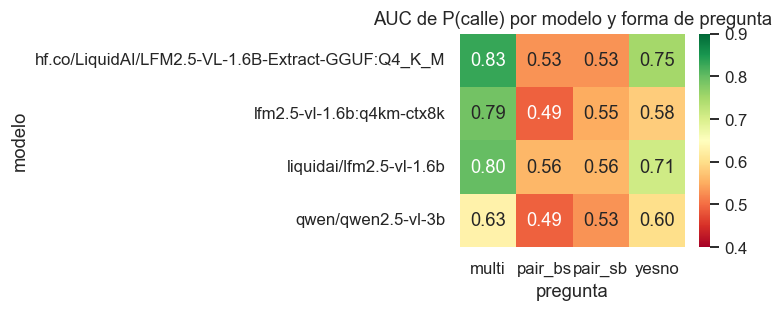

In [10]:
P = pd.DataFrame(read_jsonl(MAPPROBE / 'patches.jsonl'))
A_ = pd.DataFrame(read_jsonl(MAPPROBE / 'answers.jsonl'))
A_ = A_[A_['label'].isin(['ground', 'raised']) & A_['error'].isna()]
print('parches etiquetados:', P['label'].value_counts().to_dict())
filas = []
for (m, q), g in A_.groupby(['model', 'question']):
    y = (g['label'] == 'ground').tolist()
    filas.append({'modelo': m, 'pregunta': q, 'n': len(g), 'exactitud bal.': R.balanced_accuracy(y, g['pred_ground'].astype(bool).tolist()),
                  'AUC P(calle)': R.auc(g['p_ground'].tolist(), y), 'respuestas': dict(collections.Counter(g['answer']))})
t7 = pd.DataFrame(filas).round(2)
display(t7)
piv = t7.pivot(index='modelo', columns='pregunta', values='AUC P(calle)')
fig, ax = plt.subplots(figsize=(7, 3))
sns.heatmap(piv, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0.4, vmax=0.9, ax=ax); ax.set_title('AUC de P(calle) por modelo y forma de pregunta')
plt.tight_layout(); plt.show()

**Lectura.** Las preguntas binarias (`yesno`, `pair_*`) quedan en sesgo puro: casi siempre la misma respuesta, y la elección depende del orden de las opciones. Con cinco clases, LFM2.5-VL-1.6B separa calle de techo con AUC ≈ 0.8, mientras Qwen2.5-VL-3B queda en ≈ 0.63. La cuantización de vuelo (Q4_K_M, contexto 8k en Ollama) conserva la señal (AUC 0.79). **Decisión:** el planificador clasifica parches en cinco clases y puntúa con la probabilidad (`ROUTE_JUDGE=patches`), con el mismo modelo de vuelo (`ROUTE_LLM_MODEL_NAME`). El detalle del planificador está en NB4.

## §8 — `route_bench`: el plan contra la geometría de AirSim

Con las mismas candidatas que usa el planificador y su puntuación por parches, `route_bench.py` recorrió cada candidata en AirSim cada 4 m a la altura de vuelo. La candidata es libre si en ningún punto hay un obstáculo a menos de 6 m en la ventana central. El análisis completo está en NB4 §8; acá queda la cifra que sostuvo la decisión.

In [11]:
rt = metrics['questions']['ruta_mapa/patches']
print(json.dumps({k: (round(v, 3) if isinstance(v, float) else v) for k, v in rt.items() if not isinstance(v, (list, dict))}, ensure_ascii=False, indent=1))

{
 "n": 59,
 "chance": 0.5,
 "auc": 0.812,
 "loro_calibrated_balanced_accuracy": 0.735,
 "plan_clear_rate": 0.909,
 "direct_clear_rate": 0.909,
 "solvable_rate": 1.0,
 "passes": false
}


**Decisión:** el plan de ruta se activa (`ROUTE_PLAN_MODE=vlm`) sobre los mapas registrados en los escenarios con obstrucción (lotes D, E y F), donde la recta cruza estructuras. Los controles `*_clear` vuelan el manifiesto tal cual: en `citysim_clear` el plan elegía un desvío bloqueado con la recta libre.

## §9 — Lote piloto: ¿qué fuente para la capa estratégica en vuelo?

El banco dice qué fuente **juzga** bien. Falta saber si ese juicio **mejora el vuelo**. Antes de la v4 se corrió un lote de 15 corridas en `citysim_pilot` (brazo `slm`, 5 semillas emparejadas por fuente: `depth`, `vlm` y `off`) con una **regla de decisión fijada antes de correr** (CHANGELOG 2026-10-08 f, `experiments/analyze_strategic_batch.py`):

- Una fuente A aporta más que B si la mediana del avance a 400 s, en waypoints del plan, supera a la de B en **≥ 2 waypoints** **y** A gana en **≥ 4 de las 5** semillas emparejadas.
- Si ninguna diferencia cumple la regla, las fuentes son equivalentes en avance y se decide por **costo** (latencia) y **seguridad** (colisiones, DistMin).
- El *p* de Wilcoxon es solo diagnóstico: con 5 pares no puede bajar de 0.0625.

In [12]:
from scipy.stats import wilcoxon
L = pd.DataFrame(json.loads((ROOT / 'airsim-runs' / 'lote_estrategico' / 'strategic_batch_runs.json').read_text(encoding='utf-8')))
display(L.pivot(index='seed', columns='source', values='wp@400'))
res9 = L.groupby('source').agg(n=('seed', 'count'), avance_400=('wp@400', 'median'), final=('wp_final', 'median'),
                               exito=('success', 'sum'), colisiones=('collisions', 'sum'), distmin_med=('dist_min_m', 'median'),
                               deadlocks_med=('deadlocks', 'median'), latencia_ms=('lat_ms', 'median'))
display(res9)
W = L.pivot(index='seed', columns='source', values='wp@400')
for a, b in (('depth', 'off'), ('depth', 'vlm'), ('off', 'vlm')):
    dif = W[a].median() - W[b].median()
    gana_a, gana_b = int((W[a] > W[b]).sum()), int((W[b] > W[a]).sum())
    regla = (abs(dif) >= 2) and (max(gana_a, gana_b) >= 4)
    try:
        pw = wilcoxon(W[a], W[b]).pvalue if (W[a] != W[b]).any() else 1.0
    except ValueError:
        pw = float('nan')
    print(f'{a} vs {b}: diferencia de medianas {dif:+.1f} WP; gana {a} en {gana_a}, {b} en {gana_b} de 5 -> '
          f'{"una aporta mas" if regla else "equivalentes en avance"} (Wilcoxon p = {pw:.3f}, diagnostico)')

source,depth,off,vlm
seed,,,
1,13,14,13
2,13,13,10
3,13,13,14
4,13,13,13
5,11,13,13


,n,avance_400,final,exito,colisiones,distmin_med,deadlocks_med,latencia_ms
source,,,,,,,,
depth,5,13.0,15.0,3,0,5.832,0.0,107.5
off,5,13.0,15.0,5,0,4.949,0.0,NaN
vlm,5,13.0,15.0,4,0,3.295,0.0,788.0


depth vs off: diferencia de medianas +0.0 WP; gana depth en 0, off en 2 de 5 -> equivalentes en avance (Wilcoxon p = 0.500, diagnostico)
depth vs vlm: diferencia de medianas +0.0 WP; gana depth en 1, vlm en 2 de 5 -> equivalentes en avance (Wilcoxon p = 1.000, diagnostico)
off vs vlm: diferencia de medianas +0.0 WP; gana off en 2, vlm en 1 de 5 -> equivalentes en avance (Wilcoxon p = 0.750, diagnostico)


**Decisión.** Las tres fuentes son equivalentes en avance según la regla. Entonces se decide por costo y seguridad: la profundidad responde en ~0.1 s frente a ~0.8 s del VLM y mantiene más distancia mínima que el VLM. Se adopta `STRATEGIC_SOURCE=depth`. El lote no muestra ventaja de la capa estratégica frente a `off` en avance, y la v4 hereda esa lectura: el brazo `slm` es la arquitectura de dos lazos con la profundidad como fuente, no el VLM.

## §10 — Umbrales de TTC por índice de Youden (cap. 7)

`collect_ttc_dataset.py` registró, por ciclo y celda, el TTC estimado por el flujo y un TTC de referencia derivado de la profundidad, en tres escenarios guiados: aproximación frontal, cañón urbano y giros sin traslación. El evento es «colisión dentro de τ s» (TTC de referencia ≤ τ), y el puntaje de riesgo es −TTC estimado. Para cada τ se barre el umbral sobre la curva ROC y se toma el que maximiza el índice de Youden, $J = \text{sensibilidad} + \text{especificidad} - 1$.

3735 registros de celda (415 fotogramas x 9); con TTC estimado finito: 3139
correlacion de Pearson (conf > 0.15, n=2359): -0.034; Spearman: 0.53


,tau (s),positivos,AUC,"umbral TTC (Youden, s)",sensibilidad,especificidad
0,1.0,61,0.968,1.93,0.90,0.94
1,2.0,171,0.972,3.18,0.95,0.93
2,3.0,252,0.960,4.58,0.96,0.89


config/.env: TTC_EVASION_THRESHOLD = 3.2 | TTC_SAFE_THRESHOLD = 4.6


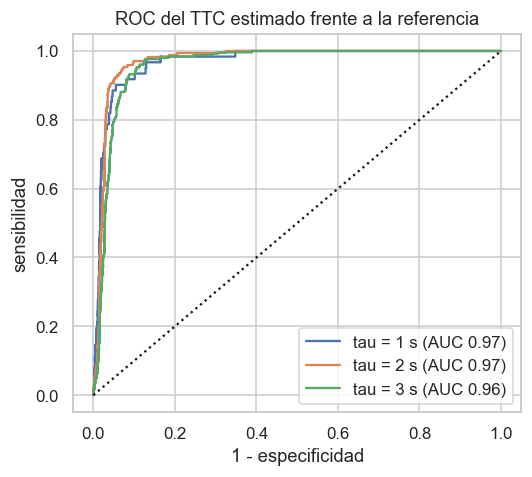

In [13]:
recs = []
for f in ('approach', 'canyon', 'yaw_only'):            # los tres escenarios del cap. 7 (yaw_sweep es el experimento D3)
    for l in open(ROOT / 'airsim-runs' / 'test' / 'ttc' / f'{f}.jsonl', encoding='utf-8'):
        d_ = json.loads(l); d_['escenario'] = f; recs.append(d_)
T = pd.DataFrame(recs)
Tf = T[T['ttc_est_s'].notna()]
print(f"{len(T)} registros de celda ({len(T) // 9} fotogramas x 9); con TTC estimado finito: {len(Tf)}")
conf = T[T['ttc_est_s'].notna() & (T['confidence'] > 0.15)]
from scipy.stats import spearmanr
print(f"correlacion de Pearson (conf > 0.15, n={len(conf)}): {np.corrcoef(conf['ttc_est_s'], conf['ttc_gt_s'])[0, 1]:+.3f}; "
      f"Spearman: {spearmanr(conf['ttc_est_s'], conf['ttc_gt_s']).statistic:.2f}")

def youden(score, y):
    th = np.unique(score)
    tpr = np.array([np.mean(score[y] >= t) for t in th]); fpr = np.array([np.mean(score[~y] >= t) for t in th])
    o = np.argsort(fpr); auc_ = np.trapezoid(tpr[o], fpr[o]) if hasattr(np, 'trapezoid') else np.trapz(tpr[o], fpr[o])
    i = int(np.argmax(tpr - fpr))
    return th[i], tpr[i], 1 - fpr[i], auc_, fpr, tpr
filas, curvas = [], {}
s_ = -Tf['ttc_est_s'].to_numpy()
for tau in (1.0, 2.0, 3.0):
    y = (Tf['ttc_gt_s'] <= tau).to_numpy()
    th, se, sp, au_, fpr, tpr = youden(s_, y)
    curvas[tau] = (fpr, tpr, au_)
    filas.append({'tau (s)': tau, 'positivos': int(y.sum()), 'AUC': round(au_, 3), 'umbral TTC (Youden, s)': round(-th, 2),
                  'sensibilidad': round(se, 2), 'especificidad': round(sp, 2)})
t10 = pd.DataFrame(filas)
display(t10)
print('config/.env: TTC_EVASION_THRESHOLD =', os.getenv('TTC_EVASION_THRESHOLD'), '| TTC_SAFE_THRESHOLD =', os.getenv('TTC_SAFE_THRESHOLD'))
fig, ax = plt.subplots(figsize=(5, 4.5))
for tau, (fpr, tpr, au_) in curvas.items():
    o = np.argsort(fpr); ax.plot(fpr[o], tpr[o], label=f'tau = {tau:.0f} s (AUC {au_:.2f})')
ax.plot([0, 1], [0, 1], 'k:'); ax.set_xlabel('1 - especificidad'); ax.set_ylabel('sensibilidad'); ax.legend()
ax.set_title('ROC del TTC estimado frente a la referencia'); plt.tight_layout(); plt.show()

**Lectura y decisión.** La correlación puntual es casi nula, pero el AUC es ≈ 0.97. El TTC estimado no sirve como cronómetro, pero **ordena** bien las celdas por riesgo, que es lo que el lazo necesita (informe §7.3). El umbral de Youden para τ = 2 s (3.18 s) es `TTC_EVASION_THRESHOLD` = 3.2 s, y el de τ = 3 s (4.58 s) es `TTC_SAFE_THRESHOLD` = 4.6 s. τ = 2 s cubre el ciclo de 0.2 s más el tiempo de iniciar la maniobra. La banda entre ambos umbrales da histéresis, que evita la oscilación entre evasión y crucero. El umbral recalculado para τ = 1 s no entra en la configuración.

## §11 — Umbral de ocupación (experimento D2)

D2 aproxima el dron a una pared lisa de TownSim a cuatro velocidades (196 fotogramas). La etiqueta es «profundidad del centro < 5 m». La curva ROC del predicado `ocupación_centro ≥ t` da el umbral por Youden.

196 fotogramas, 29 positivos; ocupacion maxima observada 0.082
AUC = 0.869; umbral de Youden = 0.0110 (TPR 0.931, FPR 0.222); con el umbral a ojo de 0.35: TPR = 0.00
config/.env: OBSTACLE_OCCUPANCY_BLOCKED = 0.011


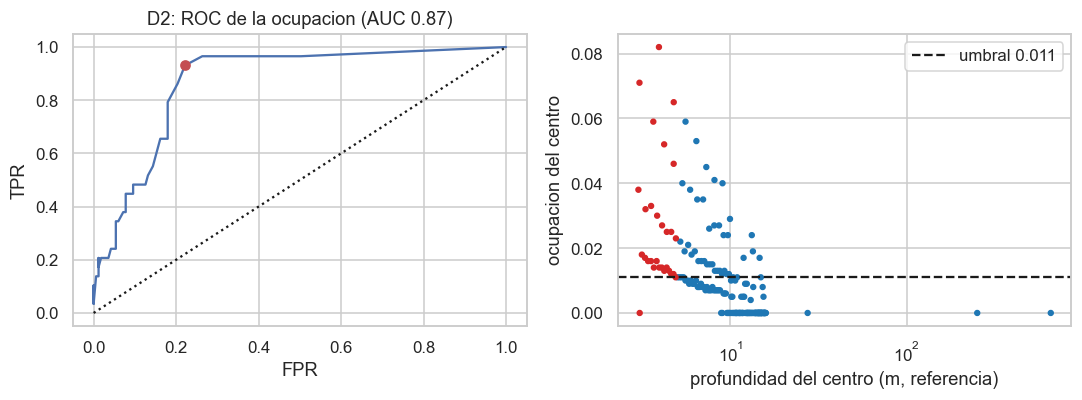

In [14]:
sys.path.insert(0, str(ROOT / 'callibration-flight'))
from d2_roc_analysis import roc_sweep
d2 = np.load(ROOT / 'd2_dataset' / 'd2_dataset_20260910_130726.npz', allow_pickle=True)
occ, gt = d2['occ_centro'], d2['gt_depth_centro']
y = gt < 5.0
th, tpr, fpr, jj = roc_sweep(occ, y)
i = int(np.argmax(jj)); o = np.argsort(fpr)
auc_d2 = np.trapezoid(tpr[o], fpr[o]) if hasattr(np, 'trapezoid') else np.trapz(tpr[o], fpr[o])
print(f"{len(occ)} fotogramas, {int(y.sum())} positivos; ocupacion maxima observada {occ.max():.3f}")
print(f"AUC = {auc_d2:.3f}; umbral de Youden = {th[i]:.4f} (TPR {tpr[i]:.3f}, FPR {fpr[i]:.3f}); con el umbral a ojo de 0.35: TPR = {np.mean(occ[y] >= 0.35):.2f}")
print('config/.env: OBSTACLE_OCCUPANCY_BLOCKED =', os.getenv('OBSTACLE_OCCUPANCY_BLOCKED'))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].plot(fpr[o], tpr[o]); ax[0].plot(fpr[i], tpr[i], 'ro'); ax[0].plot([0, 1], [0, 1], 'k:')
ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].set_title(f'D2: ROC de la ocupacion (AUC {auc_d2:.2f})')
ax[1].scatter(gt, occ, s=10, c=np.where(y, '#d62728', '#1f77b4')); ax[1].axhline(th[i], color='k', ls='--', label=f'umbral {th[i]:.3f}')
ax[1].set_xscale('log'); ax[1].set_xlabel('profundidad del centro (m, referencia)'); ax[1].set_ylabel('ocupacion del centro'); ax[1].legend()
plt.tight_layout(); plt.show()

**Decisión.** `OBSTACLE_OCCUPANCY_BLOCKED` = 0.011. Un umbral fijado a ojo (0.35) estaría por encima de toda la ocupación observada y el canal no se dispararía nunca. Límites declarados en el informe (§7.5): una sola escena, 29 positivos y una tasa de falsos positivos de ~0.22 aceptada a cambio de sensibilidad.

## §12 — Resumen: de los datos a la configuración

In [15]:
resumen = pd.DataFrame([
    ('Banco VLM (§5)', 'ninguna de las 8 preguntas pasa; grilla AUC %.2f' % metrics['questions']['grid_prod@384/replay']['auc'],
     'el VLM no decide en vuelo', 'STRATEGIC_SOURCE != vlm, DEADLOCK_STRATEGY != deep_vlm'),
    ('Misma etiqueta, otras fuentes (§6)', 'profundidad: exactitud bal. %.2f, AUC %.2f' % (tab6.iloc[3]['exactitud bal. (regla fija)'], tab6.iloc[3]['AUC']),
     'el lazo lento usa la profundidad estimada', 'STRATEGIC_SOURCE=depth, DEADLOCK_STRATEGY=depth'),
    ('map_probe (§7)', 'LFM multi: AUC %.2f' % t7[(t7['modelo'] == 'lfm2.5-vl-1.6b:q4km-ctx8k') & (t7['pregunta'] == 'multi')]['AUC P(calle)'].iloc[0],
     'juicio por parches con el modelo de vuelo', 'ROUTE_JUDGE=patches'),
    ('route_bench (§8)', 'AUC %.2f' % rt['auc'], 'plan activo en los lotes con obstruccion', 'ROUTE_PLAN_MODE=vlm'),
    ('Lote piloto de fuentes (§9)', 'avance equivalente; latencia depth %.0f ms vs vlm %.0f ms' % (res9.loc['depth', 'latencia_ms'], res9.loc['vlm', 'latencia_ms']),
     'profundidad por costo y seguridad', 'STRATEGIC_SOURCE=depth'),
    ('TTC, Youden (§10)', 'tau 2 s -> %.2f s; tau 3 s -> %.2f s' % (t10.iloc[1]['umbral TTC (Youden, s)'], t10.iloc[2]['umbral TTC (Youden, s)']),
     'umbrales de evasion y zona segura', 'TTC_EVASION_THRESHOLD=3.2, TTC_SAFE_THRESHOLD=4.6'),
    ('D2 ocupacion (§11)', 'AUC %.2f, umbral %.3f' % (auc_d2, th[i]), 'umbral de bloqueo por ocupacion', 'OBSTACLE_OCCUPANCY_BLOCKED=0.011'),
], columns=['medicion', 'resultado (recalculado aca)', 'decision', 'configuracion'])
display(resumen)

,medicion,resultado (recalculado aca),decision,configuracion
0,Banco VLM (§5),ninguna de las 8 preguntas pasa; grilla AUC 0.53,el VLM no decide en vuelo,"STRATEGIC_SOURCE != vlm, DEADLOCK_STRATEGY != ..."
1,"Misma etiqueta, otras fuentes (§6)","profundidad: exactitud bal. 0.76, AUC 0.84",el lazo lento usa la profundidad estimada,"STRATEGIC_SOURCE=depth, DEADLOCK_STRATEGY=depth"
2,map_probe (§7),LFM multi: AUC 0.79,juicio por parches con el modelo de vuelo,ROUTE_JUDGE=patches
3,route_bench (§8),AUC 0.81,plan activo en los lotes con obstruccion,ROUTE_PLAN_MODE=vlm
4,Lote piloto de fuentes (§9),avance equivalente; latencia depth 108 ms vs v...,profundidad por costo y seguridad,STRATEGIC_SOURCE=depth
5,"TTC, Youden (§10)",tau 2 s -> 3.18 s; tau 3 s -> 4.58 s,umbrales de evasion y zona segura,"TTC_EVASION_THRESHOLD=3.2, TTC_SAFE_THRESHOLD=4.6"
6,D2 ocupacion (§11),"AUC 0.87, umbral 0.011",umbral de bloqueo por ocupacion,OBSTACLE_OCCUPANCY_BLOCKED=0.011
